# PrintGPT agentic MVP: from scan to approved A4 overlay

This notebook makes the integrated agentic system observable. It runs the complete offline path, visualizes every safety boundary, explains why one candidate is revised, and proves that export contains only validated new ink.

The **agentic** part is a bounded LangGraph workflow: generation, deterministic validation, visual criticism, one optional revision, and ranking. The model proposes; deterministic geometry and an explicit human approval gate decide what may become printable.

> The notebook uses 100 DPI for fast, compact visualization. Production defaults to 300 DPI. Physical A4 dimensions remain 210 × 297 mm in either case.


In [1]:
from __future__ import annotations

from html import escape
import json
from pathlib import Path
import sys

import cv2
import numpy as np
from IPython.display import HTML, display
from PIL import Image, ImageDraw, ImageFont
import pypdfium2 as pdfium

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'pyproject.toml').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'pyproject.toml').is_file():
    raise RuntimeError('Run this notebook from the PrintGPT repository or notebooks directory')

SOURCE_ROOT = PROJECT_ROOT / 'src'
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from printgpt_alignment import A4CalibrationLayout, mm_to_px
from printgpt_alignment.calibration_page import render_calibration_image
from printgpt_mvp import approve_and_export, rectangular_allowed_region, run_offline_document

LAYOUT = A4CalibrationLayout(dpi=100.0)
ARTIFACTS = PROJECT_ROOT / 'artifacts' / 'mvp_agentic_notebook'
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print(f'Repository: {PROJECT_ROOT}')
print(f'Artifacts:  {ARTIFACTS}')
print(f'Notebook raster: {LAYOUT.raster_width_px} × {LAYOUT.raster_height_px} px at {LAYOUT.dpi:.0f} DPI')


Repository: C:\Users\saroy\.codex\.chatgpt-projects\g-p-6ac100c5e2288191adc2622b49cf9877\PrintGPT-mvp-integration
Artifacts:  C:\Users\saroy\.codex\.chatgpt-projects\g-p-6ac100c5e2288191adc2622b49cf9877\PrintGPT-mvp-integration\artifacts\mvp_agentic_notebook
Notebook raster: 827 × 1169 px at 100 DPI


## 1. The bounded agent loop

The graph has no open-ended autonomy. It creates exactly two initial candidates. Each candidate may receive at most one revision, and every path terminates in ranking. Validation always precedes criticism, so the critic sees the actual sanitized preview rather than raw model output.


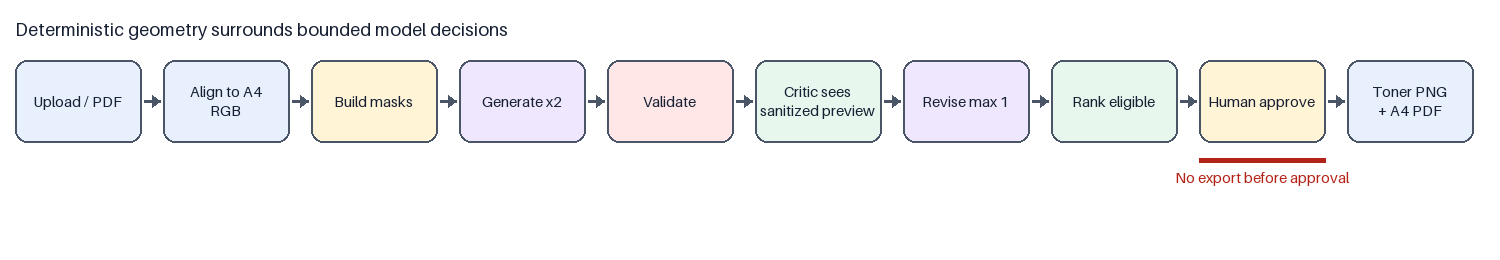

In [2]:
def workflow_diagram() -> Image.Image:
    labels = [
        ('Upload / PDF', '#e8f0fe'),
        ('Align to A4\nRGB', '#e8f0fe'),
        ('Build masks', '#fff4d6'),
        ('Generate x2', '#efe7fd'),
        ('Validate', '#ffe7e7'),
        ('Critic sees\nsanitized preview', '#e7f7ed'),
        ('Revise max 1', '#efe7fd'),
        ('Rank eligible', '#e7f7ed'),
        ('Human approve', '#fff4d6'),
        ('Toner PNG\n+ A4 PDF', '#e8f0fe'),
    ]
    canvas = Image.new('RGB', (1500, 260), 'white')
    draw = ImageDraw.Draw(canvas)
    font = ImageFont.load_default(size=18)
    small = ImageFont.load_default(size=15)
    box_w, box_h, gap, top = 126, 82, 22, 60
    for index, (label, colour) in enumerate(labels):
        x = 15 + index * (box_w + gap)
        draw.rounded_rectangle((x, top, x + box_w, top + box_h), radius=12, fill=colour, outline='#4a5568', width=2)
        draw.multiline_text((x + box_w / 2, top + box_h / 2), label, font=small, fill='#172033', anchor='mm', align='center')
        if index < len(labels) - 1:
            start = x + box_w + 3
            end = x + box_w + gap - 3
            y = top + box_h / 2
            draw.line((start, y, end, y), fill='#4a5568', width=3)
            draw.polygon([(end, y), (end - 8, y - 6), (end - 8, y + 6)], fill='#4a5568')
    draw.text((15, 18), 'Deterministic geometry surrounds bounded model decisions', font=font, fill='#172033')
    gate_x = 15 + 8 * (box_w + gap)
    draw.line((gate_x, top + box_h + 18, gate_x + box_w, top + box_h + 18), fill='#b42318', width=5)
    draw.text((gate_x + box_w / 2, top + box_h + 26), 'No export before approval', font=small, fill='#b42318', anchor='ma')
    return canvas

display(workflow_diagram())


## 2. Create a reproducible marked A4 input

A real user uploads a scan or supported PDF. For a reproducible offline demonstration, this cell creates the same kind of marked A4 page with a deliberately unfinished black drawing. The four corner markers let the alignment component recover canonical page coordinates.


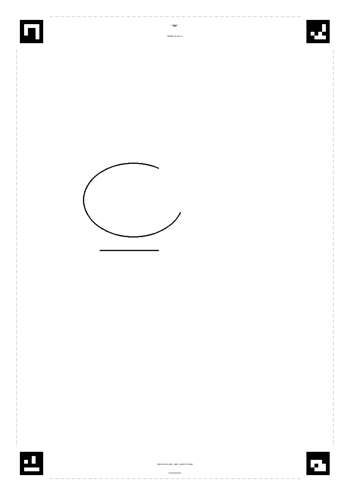

C:\Users\saroy\.codex\.chatgpt-projects\g-p-6ac100c5e2288191adc2622b49cf9877\PrintGPT-mvp-integration\artifacts\mvp_agentic_notebook\unfinished_a4_scan.png


In [3]:
def px(value_mm: float) -> int:
    return int(round(mm_to_px(value_mm, LAYOUT.dpi)))

input_gray = render_calibration_image(LAYOUT)
cv2.ellipse(input_gray, (px(80), px(120)), (px(30), px(22)), 0, 20, 300, 20, max(2, px(0.6)))
cv2.line(input_gray, (px(60), px(150)), (px(95), px(150)), 20, max(2, px(0.6)))
input_path = ARTIFACTS / 'unfinished_a4_scan.png'
if not cv2.imwrite(str(input_path), input_gray):
    raise OSError(f'Could not write {input_path}')

display(Image.fromarray(input_gray).resize((350, 495)))
print(input_path)


## 3. Run alignment, masking, generation, validation, criticism, and selection

The allowed completion area is explicit; missing region information is an error. Track A then subtracts protected existing ink, printer margins, markers, quiet zones, labels, and layout guides. The integrated run uses the real Track A validator—not the simulated test double.


In [4]:
allowed = rectangular_allowed_region(
    x_mm=40, y_mm=60, width_mm=130, height_mm=180, layout=LAYOUT
)
run = run_offline_document(
    input_path,
    allowed,
    ARTIFACTS / 'run',
    user_prompt='',
    seed=7,
    layout=LAYOUT,
)

print(f'Alignment: {run.alignment["reason"]} (confidence {run.alignment["confidence"]:.3f})')
print(f'Run status: {run.generation.outcome.status.value}')
print(f'Real deterministic validation: {not run.generation.simulated_validation}')
print(f'Generation requests: {run.generation.counters.generation_requests}')
print(f'Critic requests: {run.generation.counters.critic_requests}')


Alignment: accepted (confidence 0.989)
Run status: candidates_ready
Real deterministic validation: True
Generation requests: 3
Critic requests: 2


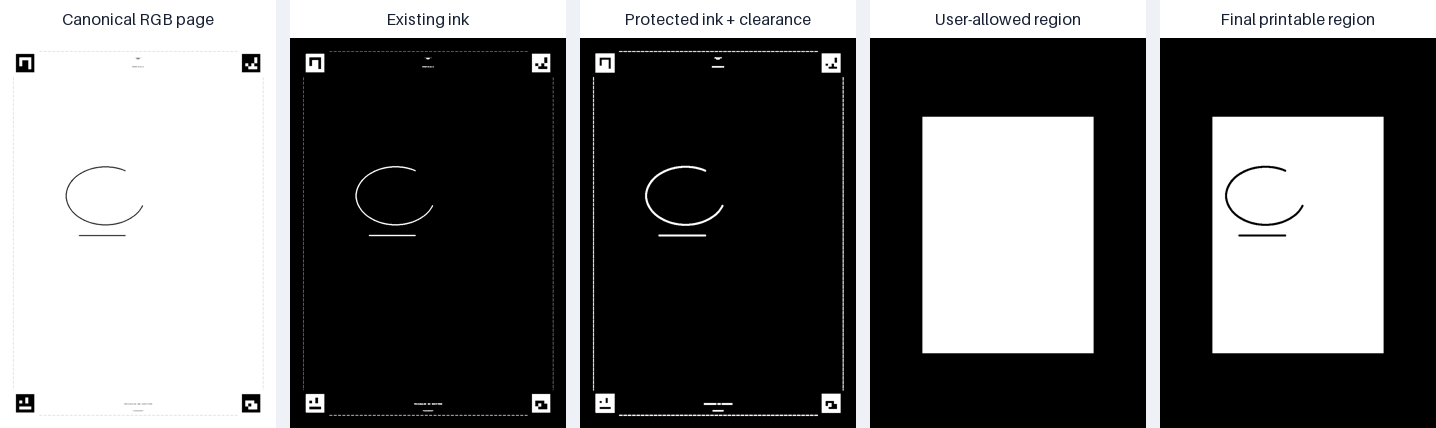

In [5]:
def labelled(image: np.ndarray, title: str, height: int = 390) -> Image.Image:
    if image.ndim == 2:
        pil = Image.fromarray(image).convert('RGB')
    else:
        pil = Image.fromarray(image)
    ratio = height / pil.height
    pil = pil.resize((max(1, round(pil.width * ratio)), height))
    panel = Image.new('RGB', (pil.width, pil.height + 38), 'white')
    panel.paste(pil, (0, 38))
    ImageDraw.Draw(panel).text((panel.width / 2, 19), title, fill='#172033', anchor='mm', font=ImageFont.load_default(size=16))
    return panel

def image_row(items: list[tuple[np.ndarray, str]], height: int = 390) -> Image.Image:
    panels = [labelled(image, title, height) for image, title in items]
    gap = 14
    row = Image.new('RGB', (sum(panel.width for panel in panels) + gap * (len(panels) - 1), max(panel.height for panel in panels)), '#eef1f5')
    x = 0
    for panel in panels:
        row.paste(panel, (x, 0))
        x += panel.width + gap
    return row

display(image_row([
    (run.canonical_page_rgb, 'Canonical RGB page'),
    (run.masks.existing_ink_mask, 'Existing ink'),
    (run.masks.protected_mask, 'Protected ink + clearance'),
    (run.masks.allowed_region_mask, 'User-allowed region'),
    (run.masks.printable_region_mask, 'Final printable region'),
]))


The printable region is the only place where proposed additions can survive. White pixels in these mask views mean membership (`255`), not white printable toner. The protected mask is intentionally wider than existing strokes, so the print overlay cannot redraw the scan.


## 4. Inspect the agents' decisions

Candidate 2 is scripted to begin outside the allowed area. Deterministic validation rejects it before the critic can see it. The graph uses that concrete failure as revision feedback, then re-runs normalization, validation, and criticism exactly once.


In [6]:
rows = []
for attempt in run.generation.attempts:
    validation = attempt.validation
    critic = attempt.critic.verdict if attempt.critic else None
    decision = attempt.revision_decision
    rows.append({
        'attempt': attempt.attempt_id,
        'kind': attempt.kind.value,
        'status': attempt.status.value,
        'validation': 'accepted' if validation and validation.accepted else ('rejected' if validation else 'not run'),
        'critic': critic.assessment.value if critic else 'not run',
        'next decision': decision.kind.value if decision else '—',
    })

headers = list(rows[0])
table = '<table><thead><tr>' + ''.join(f'<th>{escape(header)}</th>' for header in headers) + '</tr></thead><tbody>'
for row in rows:
    table += '<tr>' + ''.join(f'<td>{escape(str(row[header]))}</td>' for header in headers) + '</tr>'
table += '</tbody></table>'
display(HTML(table))


attempt,kind,status,validation,critic,next decision
candidate-1/attempt-0,initial,criticized,accepted,acceptable,keep
candidate-2/attempt-0,initial,validation_rejected,rejected,not run,revise
candidate-2/attempt-1,revision,criticized,accepted,acceptable,limit_reached


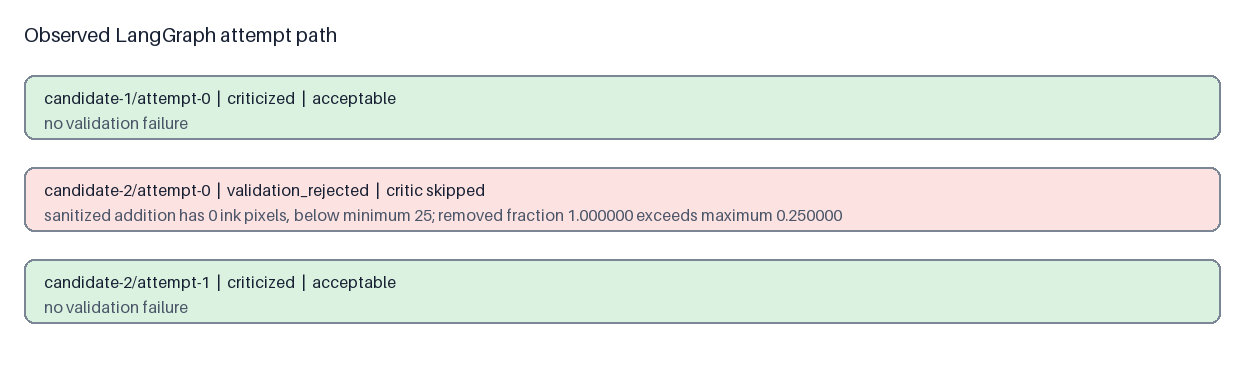

In [7]:
def attempt_timeline() -> Image.Image:
    attempts = list(run.generation.attempts)
    canvas = Image.new('RGB', (1260, 110 + 92 * len(attempts)), 'white')
    draw = ImageDraw.Draw(canvas)
    title_font = ImageFont.load_default(size=20)
    font = ImageFont.load_default(size=16)
    draw.text((24, 22), 'Observed LangGraph attempt path', fill='#172033', font=title_font)
    for index, attempt in enumerate(attempts):
        y = 75 + index * 92
        accepted = bool(attempt.validation and attempt.validation.accepted)
        colour = '#daf2df' if accepted else '#fde2e2'
        draw.rounded_rectangle((24, y, 1220, y + 64), radius=10, fill=colour, outline='#7b8794', width=2)
        critic = attempt.critic.verdict.assessment.value if attempt.critic and attempt.critic.verdict else 'critic skipped'
        reason = '; '.join(attempt.validation.reasons) if attempt.validation and attempt.validation.reasons else 'no validation failure'
        label = f'{attempt.attempt_id}  |  {attempt.status.value}  |  {critic}'
        draw.text((44, y + 13), label, fill='#172033', font=font)
        draw.text((44, y + 38), reason[:150], fill='#4a5568', font=font)
    return canvas

display(attempt_timeline())


## 5. Compare model candidates with actual sanitized previews

The left image for each candidate is the normalized complete-page provider output. It is diagnostic only. The middle image is what the critic and user actually review: the immutable canonical source with only sanitized additions composited in black. The right image isolates the sole printable source.


Rank 1: candidate-2, selected candidate-2/attempt-1, critic score 8.5


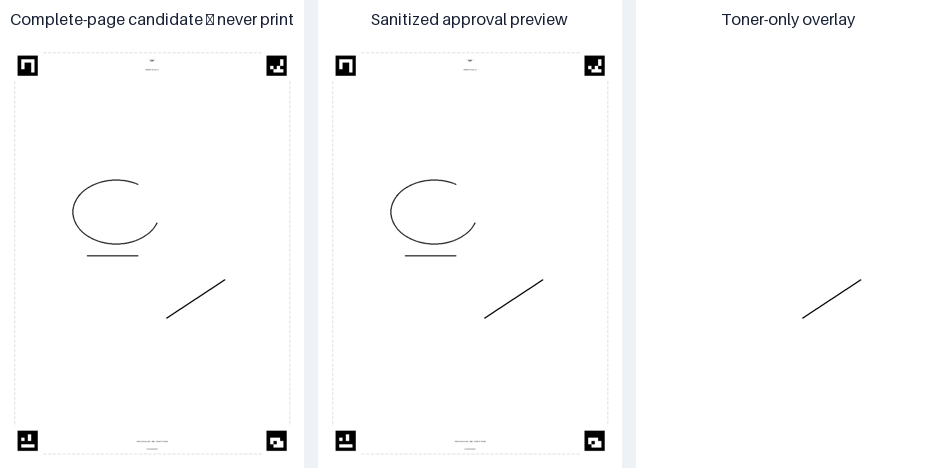

Rank 2: candidate-1, selected candidate-1/attempt-0, critic score 7.5


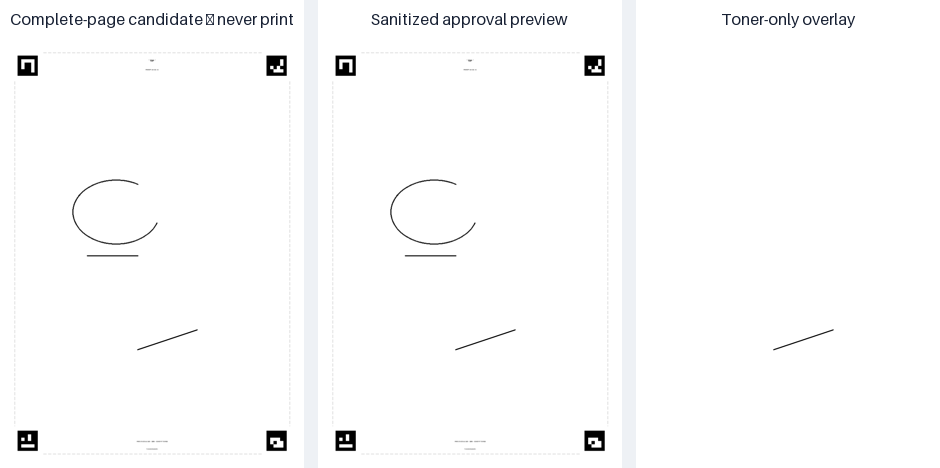

In [8]:
for candidate in run.candidates:
    attempt = candidate.attempt
    assert attempt.normalized is not None
    assert attempt.preview_rgb is not None
    assert attempt.sanitized_new_ink_mask is not None
    toner = np.full(LAYOUT.image_shape, 255, dtype=np.uint8)
    toner[attempt.sanitized_new_ink_mask == 255] = 0
    print(f'Rank {candidate.rank}: {candidate.candidate_id}, selected {candidate.attempt_id}, critic score {candidate.score:.1f}')
    display(image_row([
        (attempt.normalized.candidate_rgb, 'Complete-page candidate — never print'),
        (attempt.preview_rgb, 'Sanitized approval preview'),
        (toner, 'Toner-only overlay'),
    ], height=430))


## 6. Prove the safety invariants

These assertions are more important than a visually plausible candidate. They prove that every surviving print pixel is inside the printable region, every untouched preview pixel equals the canonical source, and the chosen attempt passed real deterministic validation.


In [9]:
proof_rows = []
for candidate in run.candidates:
    attempt = candidate.attempt
    mask = attempt.sanitized_new_ink_mask
    untouched = mask == 0
    checks = {
        'accepted by Track A': bool(attempt.validation and attempt.validation.accepted and not attempt.validation.simulated),
        'zero pixels outside printable region': not np.any((mask == 255) & (run.masks.printable_region_mask == 0)),
        'source preserved outside new ink': np.array_equal(attempt.preview_rgb[untouched], run.canonical_page_rgb[untouched]),
        'mask is exactly binary': set(np.unique(mask).tolist()).issubset({0, 255}),
    }
    assert all(checks.values())
    proof_rows.append((candidate.candidate_id, checks))

for candidate_id, checks in proof_rows:
    print(candidate_id)
    for name, passed in checks.items():
        print(f'  [{"PASS" if passed else "FAIL"}] {name}')


candidate-2
  [PASS] accepted by Track A
  [PASS] zero pixels outside printable region
  [PASS] source preserved outside new ink
  [PASS] mask is exactly binary
candidate-1
  [PASS] accepted by Track A
  [PASS] zero pixels outside printable region
  [PASS] source preserved outside new ink
  [PASS] mask is exactly binary


## 7. Exercise the approval gate and exact-size export

Ranking is not approval. First we deliberately call export without approval and verify that it is blocked. Then `DEMO_APPROVAL = True` stands in for the Streamlit checkbox and button. Export rechecks rank eligibility, real validation, binary values, and exact dimensions before writing anything.


In [10]:
selected = run.suggested_candidate
assert selected is not None

try:
    approve_and_export(run, selected.attempt_id, approved=False)
except PermissionError as error:
    print(f'Blocked as expected: {error}')
else:
    raise AssertionError('Export unexpectedly bypassed approval')

DEMO_APPROVAL = True
exported = approve_and_export(run, selected.attempt_id, approved=DEMO_APPROVAL)
print(f'Approved: {selected.candidate_id} / {selected.attempt_id}')
print(f'PNG: {exported.toner_png_path}')
print(f'PDF: {exported.a4_pdf_path}')
print(exported.print_instruction)


Blocked as expected: explicit user approval is required before export
Approved: candidate-2 / candidate-2/attempt-1
PNG: C:\Users\saroy\.codex\.chatgpt-projects\g-p-6ac100c5e2288191adc2622b49cf9877\PrintGPT-mvp-integration\artifacts\mvp_agentic_notebook\run\print\approved_toner_only.png
PDF: C:\Users\saroy\.codex\.chatgpt-projects\g-p-6ac100c5e2288191adc2622b49cf9877\PrintGPT-mvp-integration\artifacts\mvp_agentic_notebook\run\print\approved_a4_actual_size.pdf
Print this PDF at 100% or Actual Size. Disable Fit, Shrink, Scale to Fit, borderless expansion, and automatic rotation.


PDF MediaBox: 595.2756 × 841.8898 points
Physical page: 210.0 × 297.0 mm — exact A4


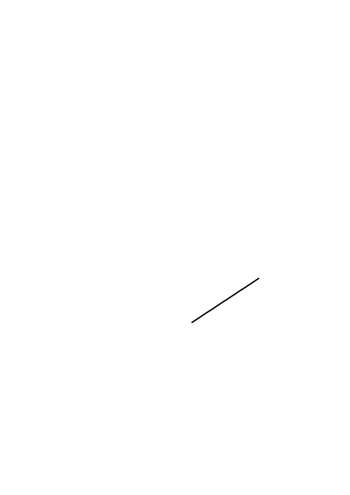

In [11]:
toner = cv2.imread(str(exported.toner_png_path), cv2.IMREAD_GRAYSCALE)
selected_mask = selected.attempt.sanitized_new_ink_mask
assert toner is not None and toner.shape == LAYOUT.image_shape
assert np.all(toner[selected_mask == 255] == 0)
assert np.all(toner[selected_mask == 0] == 255)

document = pdfium.PdfDocument(str(exported.a4_pdf_path))
try:
    width_pt, height_pt = document[0].get_size()
finally:
    document.close()

expected = (210.0 * 72.0 / 25.4, 297.0 * 72.0 / 25.4)
assert np.allclose((width_pt, height_pt), expected, atol=0.01)
print(f'PDF MediaBox: {width_pt:.4f} × {height_pt:.4f} points')
print('Physical page: 210.0 × 297.0 mm — exact A4')
display(Image.fromarray(toner).resize((350, 495)))


## What this demonstration establishes

- Alignment, masking, LangGraph generation, deterministic validation, sanitized criticism, revision, ranking, approval, and export work as one offline system.
- Two complete-page candidates are available for diagnosis, but only sanitized new-ink masks can reach export.
- A rejected proposal can be revised once; neither the critic nor a model can override geometry.
- The manifest records the selected attempt, validation evidence, approval, and exported paths.

## What remains physical

A digital 0.5 mm clearance is not a printer calibration. The real printer still needs repeated measurements of X/Y offset, scale, rotation or skew, feed-direction variation, non-printable margins, and run-to-run repeatability. Print the PDF at **100% / Actual Size**, with fitting, shrinking, borderless expansion, and automatic rotation disabled.
